# Measuring and deriving the period of a nonlinear pendulum

This tutorial studies the same scientific quantity—the period of a nonlinear pendulum—through three complementary routes: numerical integration of an ordinary differential equation (ODE), symbolic analysis with SymPy, and adaptive quadrature with SciPy. The final comparison is a cross-check of the implementations, not a validation of the idealized physical model.

The notebook is intended for an instructor-led or self-paced session of approximately 45–60 minutes. It uses the repository's standard Pixi environment; no notebook-local installation is required.

## Objectives

After working through the notebook, you should be able to:

- use a `solve_ivp` event to record physically meaningful state crossings without imposing an output grid;
- estimate a period from successive same-phase events and assess its numerical stability;
- use SymPy to derive the nonlinear equation of motion and reduce the period to an elliptic integral;
- evaluate the resulting integral with `scipy.integrate.quad` and interpret its error estimate;
- compare independent numerical routes while distinguishing numerical agreement from physical-model validity.

## Physical model

Consider a point mass $M$ attached to a massless rigid rod of length $L$. The angle $\theta(t)$ is measured from the downward vertical at time $t$, and $g$ is the gravitational acceleration. With no damping or forcing, the equation of motion and initial conditions are

$$
\ddot{\theta}(t) = -\frac{g}{L}\sin\theta(t),
\qquad
\theta(0)=\theta_0,
\qquad
\dot{\theta}(0)=0.
$$

Here, $\theta_0$ is the positive release angle, restricted to $0<\theta_0<\pi$. At $\theta_0=\pi$, the ideal pendulum is exactly at an unstable equilibrium and does not begin to move.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import quad, solve_ivp

sp.init_printing()

In [2]:
L = 1.0  # m
g = 9.81  # m / s**2
T_0 = 2*np.pi*np.sqrt(L/g)

print(f"Small-angle period: {T_0:.6f} s")

Small-angle period: 2.006067 s


## Measuring the period with ODE events

Introduce the angular velocity $\omega=\dot{\theta}$ to obtain the first-order system

$$
\dot{\theta}=\omega,
\qquad
\dot{\omega}=-\frac{g}{L}\sin\theta.
$$

A downward passage through $\theta=0$ defines a reproducible phase of the motion. The event function returns $\theta$; `direction = -1` retains only crossings with decreasing angle, and `terminal = False` records several cycles. Successive retained events are therefore separated by one full period.

In [3]:
def integrate_pendulum(
    theta_0: float,
    *,
    duration: float = 30.0,
    L: float = L,
    g: float = g,
    rtol: float = 1e-10,
    atol: float = 1e-12,
    max_step: float = np.inf,
):
    """Integrate an ideal pendulum and record downward zero crossings."""
    if not 0 < theta_0 < np.pi:
        raise ValueError("theta_0 must lie between 0 and pi radians")

    def right_hand_side(_time, state):
        theta, omega = state
        return (
            omega,
            -(g/L)*np.sin(theta),
        )

    def downward_zero_crossing(_time, state):
        theta, _omega = state
        return theta

    downward_zero_crossing.direction = -1
    downward_zero_crossing.terminal = False

    solution = solve_ivp(
        right_hand_side,
        t_span=(0.0, duration),
        y0=(theta_0, 0.0),
        events=downward_zero_crossing,
        rtol=rtol,
        atol=atol,
        max_step=max_step,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    return solution


def periods_from_events(solution) -> np.ndarray:
    """Return periods between successive downward zero crossings."""
    crossing_times = solution.t_events[0]
    if crossing_times.size < 2:
        raise RuntimeError("At least two downward crossings are required")
    return np.diff(crossing_times)

`solve_ivp` locates event roots using its internal continuous approximation. The event times therefore need not coincide with entries in `solution.t`, and no `t_eval` output grid is needed. This avoids adding a sampling-interval error to the period estimate.

In [4]:
theta_0 = np.deg2rad(120.0)
solution = integrate_pendulum(theta_0)
crossing_times = solution.t_events[0]
observed_periods = periods_from_events(solution)

print("First five downward crossings [s]:", crossing_times[:5])
print("First four observed periods [s]:", observed_periods[:4])
print(f"Median observed period: {np.median(observed_periods):.10f} s")
print(f"Period spread: {np.ptp(observed_periods):.3e} s")

First five downward crossings [s]: [ 0.68852246  3.44261229  6.19670211  8.95079194 11.70488177]
First four observed periods [s]: [2.75408983 2.75408983 2.75408983 2.75408983]
Median observed period: 2.7540898278 s
Period spread: 1.838e-09 s


### Trajectory and detected events

The plotted points are the solver's adaptive time steps. The orange markers show the independently located downward zero crossings.

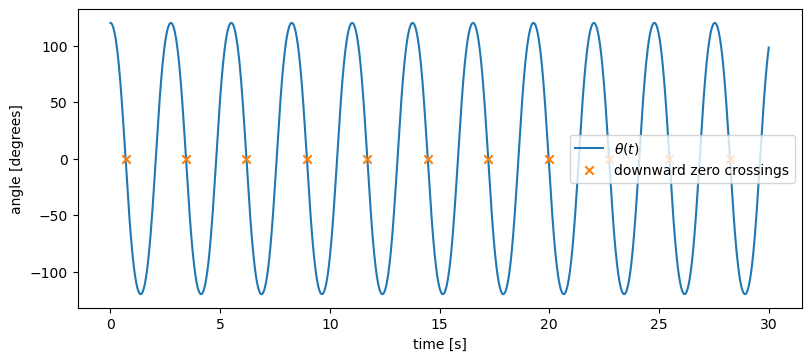

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(solution.t, np.rad2deg(solution.y[0]), label=r"$\theta(t)$")
ax.scatter(
    crossing_times,
    np.zeros_like(crossing_times),
    color="tab:orange",
    marker="x",
    zorder=3,
    label="downward zero crossings",
)
ax.set(xlabel="time [s]", ylabel="angle [degrees]")
ax.legend();

## Symbolic derivation of the period

SymPy can derive the equation of motion from the Lagrangian $\mathcal{L}=K-U$. Here, $K$ is the kinetic energy and $U$ is the gravitational potential energy, with $U=0$ at the lowest point:

$$
K=\frac{1}{2}ML^2\dot{\theta}^2,
\qquad
U=MgL(1-\cos\theta).
$$

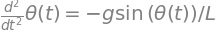

In [6]:
time = sp.symbols("t", real=True)
M, L_symbol, g_symbol = sp.symbols(
    "M L g", positive=True
)
theta_t = sp.Function(r"\theta")(time)
theta_dot = sp.diff(theta_t, time)
theta_ddot = sp.diff(theta_t, time, 2)

K = M*L_symbol**2*theta_dot**2/2
U = M*g_symbol*L_symbol*(1 - sp.cos(theta_t))
lagrangian = K - U

euler_lagrange = sp.simplify(
    sp.diff(sp.diff(lagrangian, theta_dot), time)
    - sp.diff(lagrangian, theta_t)
)
acceleration = sp.solve(sp.Eq(euler_lagrange, 0), theta_ddot)[0]
sp.Eq(theta_ddot, acceleration)

For the conservative system, equate the energy at a general angle $\theta$ with the energy at release. SymPy returns both square-root branches for the angular velocity $\omega=\dot{\theta}$. The negative branch describes the initial motion from positive $\theta_0$ towards the origin; selecting it requires physical information that is not contained in the algebra.

In [7]:
theta, theta_0, omega = sp.symbols(
    r"\theta \theta_0 \omega", real=True
)
E = M*L_symbol**2*omega**2/2 + M*g_symbol*L_symbol*(1 - sp.cos(theta))
E_0 = E.subs({theta: theta_0, omega: 0})
omega_branches = sp.solve(sp.Eq(E, E_0), omega)
omega_branches

Using the negative branch and integrating $dt=d\theta/\dot{\theta}$ over one quarter-cycle gives

$$
\frac{T}{4}
=\sqrt{\frac{L}{2g}}
\int_0^{\theta_0}
\frac{d\theta}{\sqrt{\cos\theta-\cos\theta_0}},
$$

where $T$ is the period. Introduce the integration variable $\phi$ through

$$
\sin\left(\frac{\theta}{2}\right)
=k\sin\phi,
\qquad
k=\sin\left(\frac{\theta_0}{2}\right).
$$

The quarter-period becomes a complete elliptic integral with modulus $k$. SymPy can evaluate this standard form exactly, although its `elliptic_k` function expects the squared modulus $k^2$ as its argument.

In [8]:
phi = sp.symbols(r"\phi", real=True)
k = sp.symbols("k", nonnegative=True)
integrand = 1/sp.sqrt(1 - k**2*sp.sin(phi)**2)
K_complete = sp.integrate(integrand, (phi, 0, sp.pi/2))
assert sp.simplify(K_complete - sp.elliptic_k(k**2)) == 0

T = 4*sp.sqrt(L_symbol/g_symbol)*K_complete
sp.Eq(sp.Symbol("T"), T)

Thus the nonlinear pendulum has no solution in elementary functions, but its period has the exact representation

$$
T(\theta_0)=4\sqrt{\frac{L}{g}}
K\!\left(\sin^2\frac{\theta_0}{2}\right),
$$

where the argument passed to SymPy's complete elliptic integral is the squared modulus $k^2=\sin^2(\theta_0/2)$. The integration variable remains $\phi$; $k$ is a dimensionless quantity fixed by the release angle. The full trajectory can likewise be expressed with Jacobi elliptic functions.

## Evaluating the period by quadrature

The transformed integral is well suited to adaptive quadrature for $0<\theta_0<\pi$. The function below returns both the period and SciPy's estimate of the absolute quadrature error after applying the dimensional prefactor.

In [9]:
def period_by_quadrature(
    theta_0: float,
    *,
    L: float = L,
    g: float = g,
) -> tuple[float, float]:
    """Return the pendulum period and estimated quadrature error."""
    if not 0 < theta_0 < np.pi:
        raise ValueError("theta_0 must lie between 0 and pi radians")

    k = np.sin(theta_0/2)

    def integrand(phi):
        return 1/np.sqrt(1 - k**2*np.sin(phi)**2)

    integral, error_estimate = quad(
        integrand,
        0.0,
        np.pi/2,
        epsabs=1e-12,
        epsrel=1e-12,
    )
    scale = 4*np.sqrt(L/g)
    return scale * integral, scale * error_estimate

In [10]:
for angle_degrees in (10, 60, 120, 170):
    period, error_estimate = period_by_quadrature(
        np.deg2rad(angle_degrees)
    )
    relative_to_small_angle = period/T_0 - 1
    print(
        f"{angle_degrees:3d} degrees: {period:.10f} s; "
        f"quadrature error estimate {error_estimate:.2e} s; "
        f"{relative_to_small_angle:.1%} above the small-angle period"
    )

 10 degrees: 2.0098926273 s; quadrature error estimate 2.23e-14 s; 0.2% above the small-angle period
 60 degrees: 2.1528746669 s; quadrature error estimate 2.39e-14 s; 7.3% above the small-angle period
120 degrees: 2.7540898289 s; quadrature error estimate 3.06e-14 s; 37.3% above the small-angle period
170 degrees: 4.8935242741 s; quadrature error estimate 5.43e-14 s; 143.9% above the small-angle period


The error returned by `quad` estimates numerical quadrature error only. It does not include uncertainty in $L$ or $g$, error in the initial angle, or inadequacy of the point-mass, rigid-rod, undamped model.

## Comparing the independent numerical routes

For each release angle, summarize the ODE period by the median interval between successive downward crossings. Compare it with the quadrature period using the relative discrepancy

$$
\delta=\frac{|T_{\mathrm{ODE}}-T_{\mathrm{quad}}|}{T_{\mathrm{quad}}},
$$

where $T_{\mathrm{ODE}}$ and $T_{\mathrm{quad}}$ are the periods obtained from event detection and quadrature, respectively.

In [11]:
angles_degrees = np.array([10.0, 30.0, 60.0, 90.0, 120.0, 150.0, 170.0])
quadrature_periods = []
ode_periods = []
relative_discrepancies = []

print(" angle    quadrature [s]       ODE [s]       relative discrepancy")
for angle_degrees in angles_degrees:
    theta_0 = np.deg2rad(angle_degrees)
    T_quad, _error = period_by_quadrature(theta_0)
    ode_solution = integrate_pendulum(theta_0)
    T_ode = np.median(periods_from_events(ode_solution))
    delta = abs(T_ode - T_quad)/T_quad

    quadrature_periods.append(T_quad)
    ode_periods.append(T_ode)
    relative_discrepancies.append(delta)
    print(
        f"{angle_degrees:5.0f}    {T_quad:14.10f}    "
        f"{T_ode:12.10f}    {delta:12.3e}"
    )

quadrature_periods = np.asarray(quadrature_periods)
ode_periods = np.asarray(ode_periods)
relative_discrepancies = np.asarray(relative_discrepancies)

assert np.all(relative_discrepancies < 1e-8)

 angle    quadrature [s]       ODE [s]       relative discrepancy
   10      2.0098926273    2.0098926273       3.079e-12
   30      2.0409898895    2.0409898895       2.241e-11
   60      2.1528746669    2.1528746666       1.295e-10
   90      2.3678419476    2.3678419467       3.587e-10
  120      2.7540898289    2.7540898278       3.910e-10
  150      3.5350981864    3.5350981832       8.982e-10
  170      4.8935242741    4.8935242571       3.469e-09


   30      2.0409898895    2.0409898895       2.241e-11


   60      2.1528746669    2.1528746666       1.295e-10


   90      2.3678419476    2.3678419467       3.587e-10
  120      2.7540898289    2.7540898278       3.910e-10


  150      3.5350981864    3.5350981832       8.982e-10


  170      4.8935242741    4.8935242571       3.469e-09


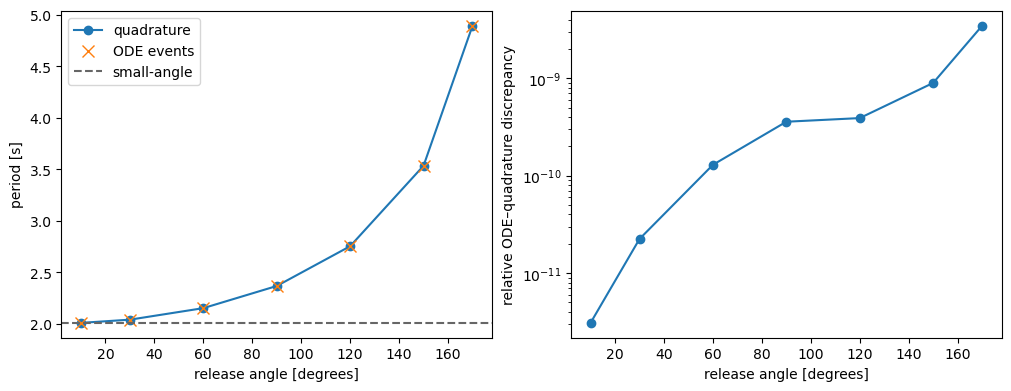

In [12]:
fig, axes = plt.subplots(
    ncols=2, figsize=(10, 3.8), constrained_layout=True
)

axes[0].plot(
    angles_degrees, quadrature_periods, "o-", label="quadrature"
)
axes[0].plot(
    angles_degrees, ode_periods, "x", markersize=8, label="ODE events"
)
axes[0].axhline(
    T_0, color="0.4", linestyle="--", label="small-angle"
)
axes[0].set(xlabel="release angle [degrees]", ylabel="period [s]")
axes[0].legend()

axes[1].semilogy(angles_degrees, relative_discrepancies, "o-")
axes[1].set(
    xlabel="release angle [degrees]",
    ylabel="relative ODE–quadrature discrepancy",
);

## Sensitivity to ODE tolerances

The ODE solver's `rtol` and `atol` are local error-control parameters, not direct bounds on the period error. An empirical tolerance study is therefore more informative than interpreting either setting as a promised number of correct digits.

In [13]:
theta_0 = np.deg2rad(120.0)
T_reference, _error = period_by_quadrature(theta_0)

print("   rtol       ODE period [s]     relative discrepancy    steps")
for relative_tolerance in (1e-4, 1e-6, 1e-8, 1e-10):
    tolerance_solution = integrate_pendulum(
        theta_0,
        rtol=relative_tolerance,
        atol=relative_tolerance * 1e-2,
    )
    T_ode = np.median(periods_from_events(tolerance_solution))
    delta = abs(T_ode - T_reference)/T_reference
    print(
        f"{relative_tolerance:8.0e}    {T_ode:14.10f}    "
        f"{delta:12.3e}    {tolerance_solution.t.size:5d}"
    )

   rtol       ODE period [s]     relative discrepancy    steps
   1e-04      2.7532120743       3.187e-04      135
   1e-06      2.7540804518       3.405e-06      374
   1e-08      2.7540897261       3.733e-08      937
   1e-10      2.7540898278       3.910e-10     2357


   1e-10      2.7540898278       3.910e-10     2357


## Interpretation and limitations

- Close agreement is useful cross-validation because the ODE and quadrature calculations fail in different ways. It is not proof that either implementation is correct, and it does not validate the physical assumptions.
- Event detection searches for roots crossed during solver steps. Multiple roots within one step, or a root touched without a sign change, can be missed. Reducing `max_step` is a useful diagnostic when the event structure is uncertain, but imposing it indiscriminately wastes work.
- As $\theta_0\rightarrow\pi$, the period diverges and both approaches become more demanding. Any fixed integration duration will eventually contain too few crossings to estimate a period.
- At exactly $\theta_0=\pi$, the mathematical initial condition is an unstable equilibrium. Numerical round-off or physical perturbations change the practical behavior, but those perturbations are not part of this ideal model.
- Damping or forcing destroys the conservative quadrature formula. Event times remain useful, but successive intervals need not be equal and may become the quantity of scientific interest.

## Further investigations

The following extensions require methodological choices rather than transcription:

- Compare event-based periods with periods inferred from sign changes on several `t_eval` grids. Quantify how the grid spacing contaminates the latter estimate.
- Approach the separatrix systematically and measure period, number of ODE steps, quadrature evaluations, and wall-clock time. Decide which quantities provide a defensible comparison.
- Add weak damping and use successive downward crossings to characterize the evolving period. Explain precisely why the conservative quadrature result ceases to be an appropriate reference.
- Compare the quadrature result with `scipy.special.ellipk`. Note that `ellipk` accepts the squared modulus $k^2$, not $k$ itself.

## Conclusions

The event-based ODE calculation measures the period directly from simulated motion, while the symbolic derivation exposes the conserved structure that reduces the problem to quadrature. Agreement between the resulting periods increases confidence in the implementations. Their shared assumptions—an ideal, conservative pendulum—remain a separate question that must be assessed against the intended physical application.